In [2]:
import torch
from transformers import BertTokenizer, BertModel
import os, random, urllib.request
import numpy as np
import pandas as pd
from collections import Counter
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)


Device: cuda


In [3]:
BASE_URL = (
    "https://raw.githubusercontent.com/facebookresearch/SentEval/"
    "main/data/probing/{}"
)
FILES = ["sentence_length.txt", "bigram_shift.txt", "subj_number.txt"]
DATA_DIR = "probing_data"
os.makedirs(DATA_DIR, exist_ok=True)

for fname in FILES:
    dest = os.path.join(DATA_DIR, fname)
    if not os.path.exists(dest):
        print(f"Downloading {fname} …")
        urllib.request.urlretrieve(BASE_URL.format(fname), dest)
        print(f"  Saved to {dest}")
    else:
        print(f"{fname} already present.")


  Saved to probing_data\sentence_length.txt
  Saved to probing_data\bigram_shift.txt
  Saved to probing_data\subj_number.txt


In [4]:
def load_balanced(filepath, n_total=50_000, seed=42):
    """
    Each line: split TAB label TAB sentence
    Returns (sentences, labels) balanced across classes.
    """
    records = []
    with open(filepath, encoding="utf-8") as f:
        for line in f:
            parts = line.strip().split("\t")
            if len(parts) < 3:
                continue
            label, sentence = parts[1], parts[2]
            records.append((sentence, label))

    df = pd.DataFrame(records, columns=["sentence", "label"])
    classes = df["label"].unique()
    n_per_class = n_total // len(classes)

    balanced = []
    rng = np.random.default_rng(seed)
    for cls in classes:
        subset = df[df["label"] == cls]
        chosen = subset.sample(
            n=min(n_per_class, len(subset)), random_state=seed
        )
        balanced.append(chosen)

    balanced_df = pd.concat(balanced).sample(frac=1, random_state=seed).reset_index(drop=True)
    print(f"{os.path.basename(filepath)}: {len(balanced_df)} samples, "
          f"classes: {dict(Counter(balanced_df['label']))}")
    return balanced_df["sentence"].tolist(), balanced_df["label"].tolist()


datasets = {}
task_files = {
    "sentence_length": os.path.join(DATA_DIR, "sentence_length.txt"),
    "bigram_shift":    os.path.join(DATA_DIR, "bigram_shift.txt"),
    "subj_number":     os.path.join(DATA_DIR, "subj_number.txt"),
}

for task, fpath in task_files.items():
    sents, labels = load_balanced(fpath)
    datasets[task] = (sents, labels)


sentence_length.txt: 49998 samples, classes: {'4': 8333, '1': 8333, '0': 8333, '5': 8333, '2': 8333, '3': 8333}
bigram_shift.txt: 50000 samples, classes: {'O': 25000, 'I': 25000}
subj_number.txt: 50000 samples, classes: {'NNS': 25000, 'NN': 25000}


In [5]:
splits = {}
for task, (sents, labels) in datasets.items():
    X_train, X_test, y_train, y_test = train_test_split(
        sents, labels,
        test_size=0.10,
        random_state=SEED,
        stratify=labels          # maintain class balance
    )
    splits[task] = {
        "X_train": X_train, "y_train": y_train,
        "X_test":  X_test,  "y_test":  y_test,
    }
    print(f"{task}: train={len(X_train)}, test={len(X_test)}, "
          f"train_dist={dict(Counter(y_train))}, "
          f"test_dist={dict(Counter(y_test))}")


sentence_length: train=44998, test=5000, train_dist={'1': 7500, '2': 7500, '4': 7499, '0': 7500, '5': 7500, '3': 7499}, test_dist={'2': 833, '1': 833, '4': 834, '0': 833, '5': 833, '3': 834}
bigram_shift: train=45000, test=5000, train_dist={'I': 22500, 'O': 22500}, test_dist={'O': 2500, 'I': 2500}
subj_number: train=45000, test=5000, train_dist={'NN': 22500, 'NNS': 22500}, test_dist={'NNS': 2500, 'NN': 2500}


In [6]:
MODEL_NAME = "google/bert_uncased_L-12_H-768_A-12"   # BERT-base (lighter than bert-large)
tokenizer  = BertTokenizer.from_pretrained(MODEL_NAME)
bert_model = BertModel.from_pretrained(MODEL_NAME, output_hidden_states=True)
bert_model.eval()
bert_model.to(device)
print("BERT model loaded:", MODEL_NAME)
print(f"Number of encoder layers: 12  (+ 1 embedding layer = 13 hidden states)")


vocab.txt: 0.00B [00:00, ?B/s]

c:\Users\dhruv\Downloads\ILLM_SVNIT\venv\Lib\site-packages\huggingface_hub\file_download.py:143: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\dhruv\.cache\huggingface\hub\models--google--bert_uncased_L-12_H-768_A-12. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


config.json:   0%|          | 0.00/385 [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/440M [00:00<?, ?B/s]

BERT model loaded: google/bert_uncased_L-12_H-768_A-12
Number of encoder layers: 12  (+ 1 embedding layer = 13 hidden states)


In [7]:
def get_layer_representations(sentences, batch_size=64, max_length=64):
    """
    Returns a dict: layer_idx (1-12) -> numpy array of shape (N, 768)
    Uses the [CLS] token representation from each encoder layer.
    """
    all_hidden = {i: [] for i in range(1, 13)}   # layers 1..12

    for start in range(0, len(sentences), batch_size):
        batch = sentences[start: start + batch_size]
        enc = tokenizer(
            batch,
            padding=True,
            truncation=True,
            max_length=max_length,
            return_tensors="pt",
        )
        enc = {k: v.to(device) for k, v in enc.items()}

        with torch.no_grad():
            outputs = bert_model(**enc)          # output_hidden_states=True in config

        # outputs.hidden_states: tuple of (embedding, layer1, …, layer12)
        # shape of each: (batch, seq_len, 768)
        hidden_states = outputs.hidden_states    # tuple length 13

        for layer_idx in range(1, 13):           # 1..12  (skip embedding layer 0)
            cls_rep = hidden_states[layer_idx][:, 0, :].cpu().numpy()
            all_hidden[layer_idx].append(cls_rep)

        if (start // batch_size) % 10 == 0:
            print(f"  processed {min(start + batch_size, len(sentences))}/{len(sentences)}", end="\r")

    return {i: np.vstack(all_hidden[i]) for i in range(1, 13)}


In [8]:
results = {}   # task -> layer -> test_accuracy

for task, split in splits.items():
    print(f"\n{'='*60}")
    print(f"Task: {task}")
    print(f"{'='*60}")

    print("  Extracting TRAIN representations …")
    train_reps = get_layer_representations(split["X_train"])
    print("\n  Extracting TEST representations …")
    test_reps  = get_layer_representations(split["X_test"])

    results[task] = {}
    for layer_idx in range(1, 13):
        X_tr = train_reps[layer_idx]
        X_te = test_reps[layer_idx]
        y_tr = split["y_train"]
        y_te = split["y_test"]

        clf = LogisticRegression(max_iter=1000, random_state=SEED, C=1.0)
        clf.fit(X_tr, y_tr)
        acc = accuracy_score(y_te, clf.predict(X_te))
        results[task][layer_idx] = acc
        print(f"  Layer {layer_idx:2d}: test accuracy = {acc:.4f}")



Task: sentence_length
  Extracting TRAIN representations …


c:\Users\dhruv\Downloads\ILLM_SVNIT\venv\Lib\site-packages\transformers\models\bert\modeling_bert.py:440: UserWarning: 1Torch was not compiled with flash attention. (Triggered internally at ..\aten\src\ATen\native\transformers\cuda\sdp_utils.cpp:263.)
  attn_output = torch.nn.functional.scaled_dot_product_attention(


  processed 44864/44998
  Extracting TEST representations …
  Layer  1: test accuracy = 0.9106
  Layer  2: test accuracy = 0.9200


c:\Users\dhruv\Downloads\ILLM_SVNIT\venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


  Layer  3: test accuracy = 0.9152


c:\Users\dhruv\Downloads\ILLM_SVNIT\venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


... (13 outputs left out)

c:\Users\dhruv\Downloads\ILLM_SVNIT\venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


  Layer 11: test accuracy = 0.7728


c:\Users\dhruv\Downloads\ILLM_SVNIT\venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


  Layer 12: test accuracy = 0.7394

Task: bigram_shift
  Extracting TRAIN representations …
  processed 44864/45000
  Extracting TEST representations …
  Layer  1: test accuracy = 0.4910
  Layer  2: test accuracy = 0.5860
  Layer  3: test accuracy = 0.7554
  Layer  4: test accuracy = 0.7824
  Layer  5: test accuracy = 0.7940
  Layer  6: test accuracy = 0.7858
  Layer  7: test accuracy = 0.8156
  Layer  8: test accuracy = 0.8110
  Layer  9: test accuracy = 0.8278
  Layer 10: test accuracy = 0.8456
  Layer 11: test accuracy = 0.8490
  Layer 12: test accuracy = 0.8382

Task: subj_number
  Extracting TRAIN representations …
  processed 44864/45000
  Extracting TEST representations …
  Layer  1: test accuracy = 0.7964
  Layer  2: test accuracy = 0.8410
  Layer  3: test accuracy = 0.8514
  Layer  4: test accuracy = 0.8584
  Layer  5: test accuracy = 0.8568
  Layer  6: test accuracy = 0.8662
  Layer  7: test accuracy = 0.8756
  Layer  8: test accuracy = 0.8740
  Layer  9: test accuracy = 0.87

In [9]:
import pandas as pd

rows = []
for task, layer_accs in results.items():
    for layer, acc in layer_accs.items():
        rows.append({"Task": task, "Layer": layer, "Test Accuracy": round(acc, 4)})

df_results = pd.DataFrame(rows)
pivot = df_results.pivot(index="Layer", columns="Task", values="Test Accuracy")
print(pivot.to_string())


Task   bigram_shift  sentence_length  subj_number
Layer                                            
1            0.4910           0.9106       0.7964
2            0.5860           0.9200       0.8410
3            0.7554           0.9152       0.8514
4            0.7824           0.9128       0.8584
5            0.7940           0.8896       0.8568
6            0.7858           0.8588       0.8662
7            0.8156           0.8500       0.8756
8            0.8110           0.8426       0.8740
9            0.8278           0.8218       0.8784
10           0.8456           0.7948       0.8722
11           0.8490           0.7728       0.8590
12           0.8382           0.7394       0.8544


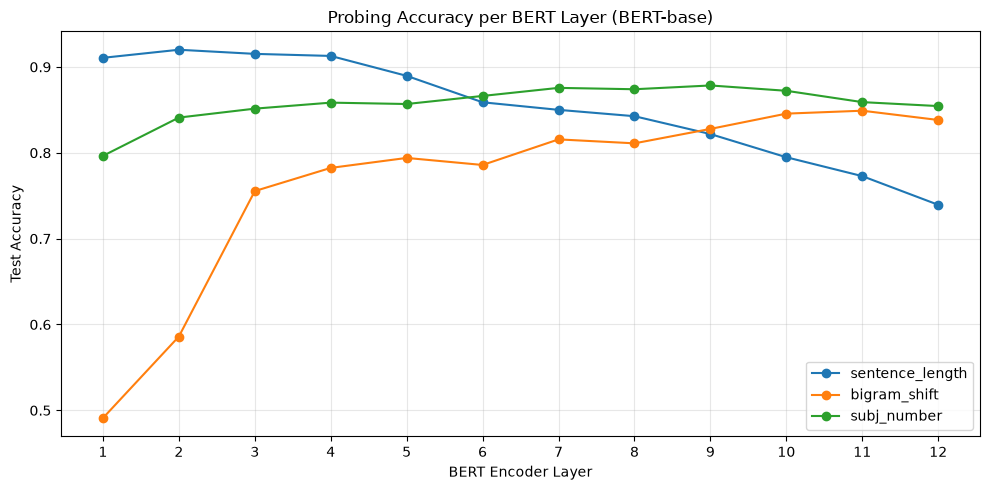

Plot saved to probing_results.png


In [10]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 5))
for task in results:
    layers = sorted(results[task].keys())
    accs   = [results[task][l] for l in layers]
    ax.plot(layers, accs, marker="o", label=task)

ax.set_xlabel("BERT Encoder Layer")
ax.set_ylabel("Test Accuracy")
ax.set_title("Probing Accuracy per BERT Layer (BERT-base)")
ax.set_xticks(range(1, 13))
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("probing_results.png", dpi=150)
plt.show()
print("Plot saved to probing_results.png")
